In [6]:
import numpy as np
import matplotlib.pyplot as plt

### Condición para que la reconstrucción sea única

La matriz $A \in \mathbb{R}^{m \times 64}$ transforma los 64 valores de los píxeles de la imagen en las $m$ mediciones obtenidas por los rayos:

$$
b = Ax
$$

Para que la imagen pueda reconstruirse de manera única, el sistema $Ax=b$ debe tener una única solución. Esto sucede cuando las 64 columnas de $A$ son linealmente independientes, es decir, cuando la matriz tiene rango columna completo:

$$
\operatorname{rango}(A)=64
$$

El espacio nulo de $A$ está formado por todos los vectores $v$ que cumplen:

$$
Av=0
$$

Si existe un vector no nulo $v$ tal que $Av=0$, entonces las imágenes representadas por $x$ y $x+v$ producen exactamente las mismas mediciones, porque:

$$
A(x+v)=Ax+Av=b+0=b
$$

Por lo tanto, las mediciones no permiten distinguir entre $x$ y $x+v$, y la reconstrucción no es única. El vector $v$ representa una modificación de la imagen que los rayos utilizados no pueden detectar.

Según el teorema de rango y nulidad:

$$
\operatorname{rango}(A)+\dim(\operatorname{Nul}(A))=64
$$

Por lo tanto:

$$
\dim(\operatorname{Nul}(A))=64-\operatorname{rango}(A)
$$

Si $\operatorname{rango}(A)=64$, entonces:

$$
\dim(\operatorname{Nul}(A))=0
$$

En ese caso, el espacio nulo contiene únicamente al vector cero y la reconstrucción puede ser única. En cambio, si $\operatorname{rango}(A)<64$, el espacio nulo contiene vectores no nulos y existen distintas imágenes capaces de producir las mismas mediciones.

Además, como:

$$
\operatorname{rango}(A)\leq \min(m,64)
$$

es necesario contar con al menos 64 rayos, es decir, $m\geq64$. Sin embargo, tener 64 rayos o más no garantiza por sí solo una reconstrucción única, ya que algunos rayos podrían aportar información repetida o linealmente dependiente.

In [7]:
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

x_fantoma = X_fantoma.reshape(-1)

def mascara_rayo(n, direccion, s):

    matriz = np.array([[0] * n for _ in range(n)])      # creamos una matriz de n x n de ceros

    for i in range(0, n):      
        for j in range(0, n):
            if direccion[0] * i + direccion[1] * j == s:        # comprobamos si el píxel (i, j) pertenece al rayo
                matriz[i, j] = 1        # si pertenece al rayo, marcamos esa posición con un 1

    return matriz       # devolvemos la máscara del rayo


def matriz_proyeccion(n, direcciones):

    matriz = []     # acá vamos a guardar los vectores de todas las máscaras
    rayo = []       # acá vamos a guardar los pares de s y (alfa, beta) de cada rayo

    for direccion in direcciones:

        valores_s = []      # acá guardamos todos los valores posibles de s para la dirección actual

        # recorremos todos los píxeles
        for i in range(n):
            for j in range(n):
                valores_s.append(direccion[0] * i + direccion[1] * j)       # calculamos el valor de s que le corresponde al píxel (i, j) para esta dirección

        valores_s = sorted(set(valores_s))      # eliminamos los valores repetidos de s y los ordenamos de menor a mayor

        for s in valores_s:

            rayo.append((tuple(direccion), s))

            mascara = mascara_rayo(n, direccion, s)     # generamos la máscara de este rayo particular
            matriz.append(mascara.reshape(-1))      # convertimos la máscara de n x n en un vector y lo agregamos como una nueva fila

    return np.array(matriz) , rayo



In [13]:
D2 = [(1, 0), (0, 1)]
A2, rayos_A2 = matriz_proyeccion(8, D2)
print (f"Dimensiones de A2: {A2.shape}")

rango_A2 = np.linalg.matrix_rank(A2)
print (f"Rango de A2: {rango_A2}")

nul_A2 = 64 - rango_A2
print(f"Dimensión del espacio nulo: {nul_A2}")

if (nul_A2 == 0):
    print ("Permite determinar una imagen de manera única!")
else :
    print ("No permite determinar una imagen de manera única!")





Dimensiones de A2: (16, 64)
Rango de A2: 15
Dimensión del espacio nulo: 49
No permite determinar una imagen de manera única!


In [14]:
D4 = D2 + [(1, 1), (1, -1)]
A4, rayos_A4 = matriz_proyeccion(8, D4)
print (f"Dimensiones de A4: {A4.shape}")

rango_A4 = np.linalg.matrix_rank(A4)
print (f"Rango de A4: {rango_A4}")

nul_A4 = 64 - rango_A4
print(f"Dimensión del espacio nulo: {nul_A4}")

if (nul_A4 == 0):
    print ("Permite determinar una imagen de manera única!")
else :
    print ("No permite determinar una imagen de manera única!")



Dimensiones de A4: (46, 64)
Rango de A4: 39
Dimensión del espacio nulo: 25
No permite determinar una imagen de manera única!


In [15]:
D7 = D4 + [(2, 1), (1, 2), (3, 1)]
A7, rayos_A7 = matriz_proyeccion(8, D7)
print (f"Dimensiones de A7: {A7.shape}")

rango_A7 = np.linalg.matrix_rank(A7)
print (f"Rango de A7: {rango_A7}")

nul_A7 = 64 - rango_A7
print(f"Dimensión del espacio nulo: {nul_A7}")

if (nul_A7 == 0):
    print ("Permite determinar una imagen de manera única!")
else :
    print ("No permite determinar una imagen de manera única!")

Dimensiones de A7: (119, 64)
Rango de A7: 64
Dimensión del espacio nulo: 0
Permite determinar una imagen de manera única!


### Comparación de las matrices de proyección

La matriz $A_2$ tiene dimensiones $16 \times 64$ y rango 15. Por lo tanto, la dimensión de su espacio nulo es 49 y no permite determinar una imagen de manera única. Además, como tiene 16 filas pero solamente 15 son linealmente independientes, presenta una medición redundante.

La matriz $A_4$ tiene dimensiones $46 \times 64$ y rango 39. En este caso, la dimensión del espacio nulo es 25, por lo que tampoco permite determinar una imagen de manera única. La diferencia entre sus 46 filas y su rango indica que existen 7 mediciones redundantes.

Finalmente, la matriz $A_7$ tiene dimensiones $119 \times 64$ y rango 64. Como alcanza el máximo rango posible y la dimensión de su espacio nulo es cero, permite determinar una imagen de manera única. Sin embargo, de las 119 mediciones, solamente 64 son linealmente independientes, por lo que las 55 restantes son redundantes y no aportan información nueva para determinar la unicidad de la solución.

En conclusión, agregar nuevas direcciones aumenta la cantidad de información disponible, pero no todos los rayos incorporados aportan información independiente. Solo en el caso de $A_7$ se alcanza rango 64 y, por lo tanto, se reúnen mediciones suficientes para reconstruir una imagen de $8 \times 8$ de manera única.


In [60]:
# SVD de A4
U, S, Vt = np.linalg.svd(A4)

# tomo el ultimo vector singular derecho de (ultima fila de Vt), que pertenece al espacio nulo
v = Vt[-1]

# verifico que ||A4v|| sea aprox 0
norma_A4v = np.linalg.norm(A4 @ v)
print(f"Norma de A4v = {norma_A4v}") # vemos que es muy chico, casi 0.

Norma de A4v = 9.4641579935908e-16


In [41]:
b4 = A4 @ x_fantoma

In [ ]:
#construyo x_alt con gamma != 0 (elijo gamma = 0.9)
gamma = 0.9
x_alt = x_fantoma + gamma*v
b_alt = A4 @ x_alt

diferencia_b = np.linalg.norm(b_alt - b4) # para ver la diferencia, calculamos la norma de la resta. seria como el abs de la resta.
print(f"Diferencia ||A4x_alt - b4|| = {diferencia_b}") # vemos que es muy chica

Diferencia ||A4x_alt - b4|| = 1.561952173388369e-15


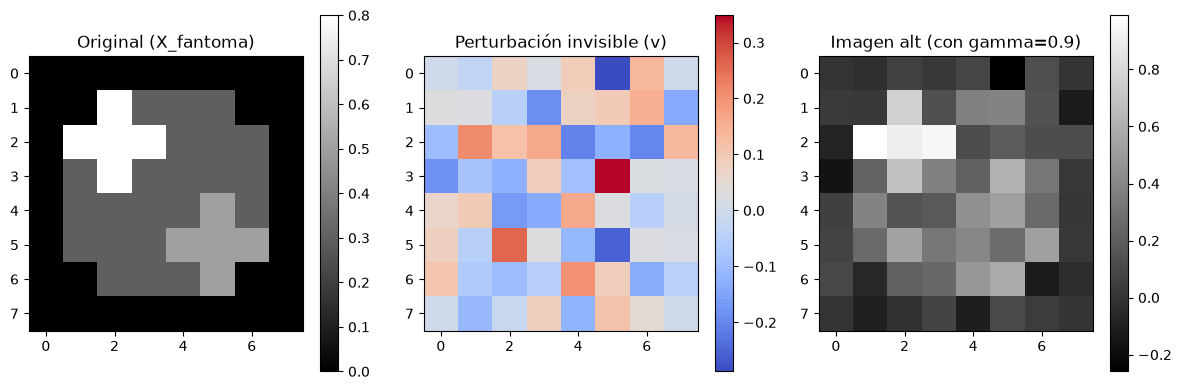

In [59]:
# visualizamos 
fig, ax = plt.subplots(1,3,figsize=(12,4))

im0 = ax[0].imshow(X_fantoma, cmap="gray")
ax[0].set_title("Original (X_fantoma)")
plt.colorbar(im0, ax=ax[0])
im1 = ax[1].imshow(v.reshape(8, 8), cmap="coolwarm")  # v es una imagen llena de valores de tal forma que en cualquier fila, col y diagonal a 45°, los rayos dan 0. pero si vemos v, nos damos cuenta que hay cosas aunque den 0.
ax[1].set_title("Perturbación invisible (v)")
plt.colorbar(im1, ax=ax[1])
im2 = ax[2].imshow(x_alt.reshape(8, 8), cmap="gray")
ax[2].set_title(f"Imagen alt (con gamma={gamma})")
plt.colorbar(im2, ax=ax[2])
plt.tight_layout()
plt.show()

##### Interpretación de la info invisible para $A_4$
Al visualizar el vector $v$ del espacio nulo como una matriz de $8x8$, se observa un patrón con valores positivos y negativos distribuidos en el plano.
Como el tomógrafo $A_4$ únicamente hace proyecciones en 4 direcciones (rayos horizontales, verticales y diagonales a $\pm 45°$), al calcular la atenuación acumulada a lo largo de cualquiera de esos rayos, las componentes positivas de $v$ se cancelan con las componentes negativas, dando como resultado 0 en cada una de las 46 mediciones.
En consecuencia, la imagen modificada $x_{alt} = x_{fantoma} + \gamma v$ difiere visiblemente de la original ($x_{fantoma}$) para el ojo humano, pero produce las mismas mediciones en el escáner ($A_4 x_{alt} \approx A_4 x_{fantoma}$). Esto demuestra que las variaciones que se compensan a lo largo de estas 4 direcciones resultan completamente invisibles para el tomógrafo 
$A_4$